# Task: auto-contouring the spleen on CT with MONAI

**Practical session, 80 minutes. Work in pairs.**

You will train a small 3D U-Net to contour one organ on CT, then do what a medical physicist does with any auto-contouring tool: measure it, and find out where it breaks.

| Time | Part | What you do |
|---|---|---|
| 0–10 min | 1. Look at the data | Open a CT, window it, overlay the reference contour |
| 10–30 min | 2. Train | Complete three lines of code, train for a fixed time budget |
| 30–50 min | 3. Evaluate | Dice, HD95, surface Dice and volume error per patient |
| 50–70 min | 4. Stress test | Noise, HU offset, thick slices, mirrored anatomy |
| 70–80 min | 5. Debrief | One failure, and the QA check that would catch it |

**Before you start:** `Runtime → Change runtime type → T4 GPU`, then run the cells in order.
Cells marked ✏️ contain a question to discuss with your partner. Cells marked `TODO` need one line of code from you.

Data: Medical Segmentation Decathlon, Task09 Spleen (CC-BY-SA 4.0). This notebook is for teaching only; nothing here is a medical device.

## 0. Setup

In [33]:
# Colab already ships PyTorch; we only add MONAI (version pinned so the session is reproducible).
!pip install -q "monai[nibabel,tqdm]==1.6.1"

In [34]:
import glob, os, time, warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

import monai
from monai.apps import download_and_extract, download_url
from monai.data import CacheDataset, DataLoader
from monai.inferers import sliding_window_inference
from monai.losses import DiceCELoss
from monai.metrics import compute_hausdorff_distance, compute_surface_dice
from monai.networks.nets import UNet
from monai.transforms import (
    Compose, CropForegroundd, EnsureChannelFirstd, LoadImaged, Orientationd,
    RandCropByPosNegLabeld, ScaleIntensityRanged, Spacingd,
)
from monai.utils import set_determinism

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("MONAI", monai.__version__, "| PyTorch", torch.__version__, "| device:", device)
if device.type != "cuda":
    print("WARNING: no GPU found. Training will be far too slow: switch the runtime to a GPU.")

MONAI 1.6.1 | PyTorch 2.14.1+cu130 | device: cuda


In [35]:
# ---- All the knobs of the session are here ----
ROOT = "/content/data" if os.path.isdir("/content") else "./data"

TRAIN_MINUTES = 10                 # time budget for Part 2
VAL_EVERY = 5                      # validate every N epochs

PIXDIM = (1.5, 1.5, 2.0)           # mm; every scan is resampled to this voxel size
HU_MIN, HU_MAX = -57.0, 164.0      # soft-tissue window fed to the network
ROI = (96, 96, 96)                 # patch size (voxels) for training and sliding-window inference
SW_BATCH = 4
BATCH_SIZE, PATCHES_PER_SCAN = 2, 4

N_TEST, N_VAL = 9, 5               # the last 9 scans are held out and never used for training
TOL_MM = 2.0                       # tolerance of the surface Dice
N_STRESS = 4                       # number of test scans used in Part 4
SEED = 0

In [36]:
# Download the dataset (about 1.5 GB, usually 1-2 minutes on Colab).
data_dir = os.path.join(ROOT, "Task09_Spleen")
if not os.path.isdir(data_dir):
    download_and_extract(
        url="https://msd-for-monai.s3-us-west-2.amazonaws.com/Task09_Spleen.tar",
        filepath=os.path.join(ROOT, "Task09_Spleen.tar"),
        output_dir=ROOT,
        hash_val="410d4a301da4e5b2f6f86ec3ddba524e",
        hash_type="md5",
    )

images = sorted(glob.glob(os.path.join(data_dir, "imagesTr", "*.nii.gz")))
labels = sorted(glob.glob(os.path.join(data_dir, "labelsTr", "*.nii.gz")))
cases = [{"image": i, "label": l} for i, l in zip(images, labels)]

test_files = cases[-N_TEST:]
val_files = cases[-(N_TEST + N_VAL):-N_TEST]
train_files = cases[:-(N_TEST + N_VAL)]
print(f"{len(cases)} labelled scans -> train {len(train_files)} | validation {len(val_files)} | test {len(test_files)}")

41 labelled scans -> train 27 | validation 5 | test 9


## 1. Look at the data (10 min)

Never train on data you have not looked at. We load one scan, bring it to a standard orientation and display it with two different HU windows.

case            : spleen_10
matrix          : (512, 512, 55)
voxel size (mm) : [0.98 0.98 5.  ]
HU range        : -1024.0 to 3072.0
spleen volume   : 253 mL
spleen voxels   : 0.37 % of the scan


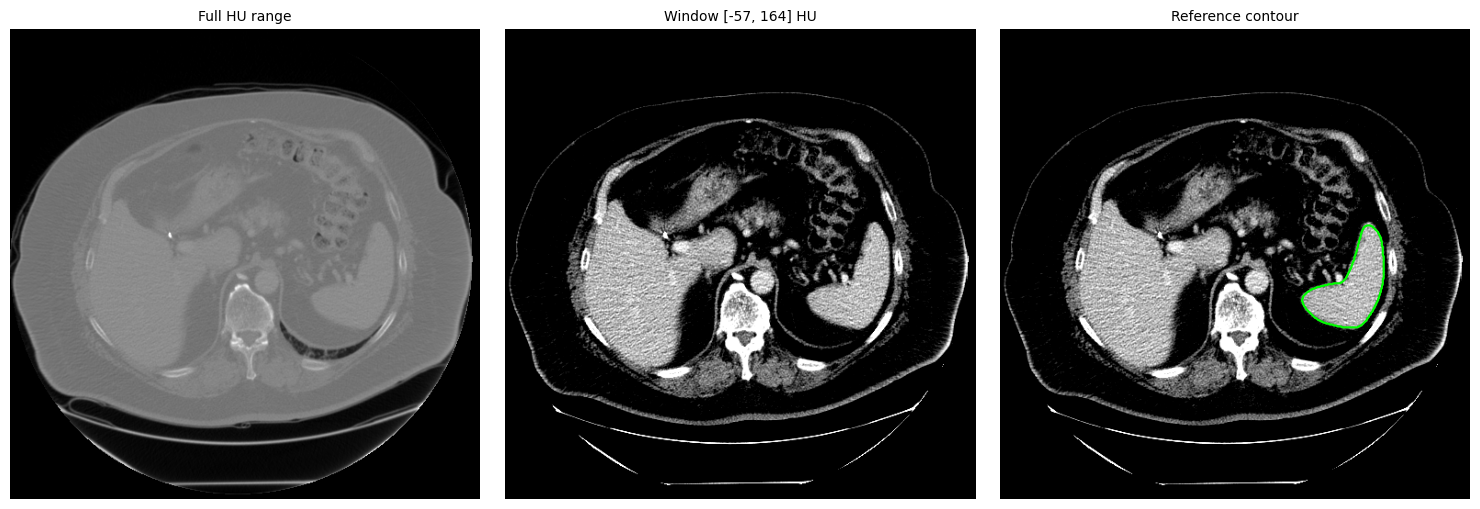

In [37]:
def case_id(d):
    return os.path.basename(d["image"]).replace(".nii.gz", "")


def show_axial(ax, img, k, vmin, vmax, title=""):
    # Axial slice in radiological convention (patient's left is on the right of the picture).
    ax.imshow(np.asarray(img)[:, :, k].T, cmap="gray", vmin=vmin, vmax=vmax, origin="lower")
    ax.invert_xaxis()
    ax.set_title(title, fontsize=10)
    ax.axis("off")


def draw_contour(ax, mask, k, color):
    m = np.asarray(mask)[:, :, k].T.astype(float)
    if m.max() > 0:
        ax.contour(m, levels=[0.5], colors=[color], linewidths=1.5)


def best_slice(mask):
    # Index of the axial slice with the largest contour.
    return int(np.asarray(mask).sum(axis=(0, 1)).argmax())


look = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image", "label"]),
    Orientationd(keys=["image", "label"], axcodes="RAS"),
])(train_files[0])
img, lab = look["image"][0], look["label"][0]
vox = np.array(look["image"].pixdim, dtype=float)

print("case            :", case_id(train_files[0]))
print("matrix          :", tuple(img.shape))
print("voxel size (mm) :", np.round(vox, 2))
print("HU range        :", float(img.min()), "to", float(img.max()))
print(f"spleen volume   : {float(lab.sum()) * vox.prod() / 1000:.0f} mL")
print(f"spleen voxels   : {100 * float(lab.sum()) / lab.numel():.2f} % of the scan")

k = best_slice(lab)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
show_axial(axes[0], img, k, -1000, 1000, "Full HU range")
show_axial(axes[1], img, k, HU_MIN, HU_MAX, f"Window [{HU_MIN:.0f}, {HU_MAX:.0f}] HU")
show_axial(axes[2], img, k, HU_MIN, HU_MAX, "Reference contour")
draw_contour(axes[2], lab, k, "lime")
plt.tight_layout(); plt.show()

✏️ **Discuss (2 min)**

1. The voxels are far from isotropic. What would a network that sees raw voxel grids learn if every hospital used a different slice thickness?
2. Less than 1 % of the voxels are spleen. A model that answers "background" everywhere has more than 99 % voxel accuracy. What does that tell you about accuracy as a metric, and about the loss function we need?
3. Why feed the network a soft-tissue window and not the full HU range?

## 2. Train a 3D U-Net (20 min)

The pipeline has three ingredients, and each one has a line for you to complete:

- **TODO 1, preprocessing:** scale the HU window to [0, 1].
- **TODO 2, loss:** Dice + cross-entropy, which copes with the class imbalance you just measured.
- **TODO 3, inference:** a whole scan does not fit in GPU memory at once, so we slide a patch-sized window over it.

Preparing the data takes a few minutes because every scan is loaded, reoriented and resampled once, then kept in memory.

In [ ]:
set_determinism(seed=SEED)

# Steps shared by training, validation and test: load, reorient, resample to a common voxel size.
common = [
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image", "label"]),
    Orientationd(keys=["image", "label"], axcodes="RAS"),
    Spacingd(keys=["image", "label"], pixdim=PIXDIM, mode=("bilinear", "nearest")),
]

train_tf = Compose(common + [
    ScaleIntensityRanged(keys="image", a_min=HU_MIN, a_max=HU_MAX, b_min=0.0, b_max=1.0, clip=True),  # (solution of TODO 1)
    CropForegroundd(keys=["image", "label"], source_key="image", allow_smaller=True),
    # Random patches, half of them centred on the spleen, half on background:
    RandCropByPosNegLabeld(keys=["image", "label"], label_key="label", spatial_size=ROI,
                           pos=1, neg=1, num_samples=PATCHES_PER_SCAN),
])
eval_tf = Compose(common)   # validation and test scans stay in HU; scaling happens inside predict()

train_ds = CacheDataset(train_files, train_tf, cache_rate=1.0, num_workers=2)
val_ds = CacheDataset(val_files, eval_tf, cache_rate=1.0, num_workers=2)
test_ds = CacheDataset(test_files, eval_tf, cache_rate=1.0, num_workers=2)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

patch = train_ds[0][0]["image"]
print("training patch:", tuple(patch.shape), "| intensity range:", float(patch.min()), "to", float(patch.max()))
assert float(patch.max()) <= 1.0 and float(patch.min()) >= 0.0, "TODO 1 is not done: intensities should be in [0, 1]."

Loading dataset:  22%|██▏       | 2/9 [00:06<00:21,  3.01s/it]

In [ ]:
def make_model():
    return UNet(
        spatial_dims=3, in_channels=1, out_channels=2,       # 2 output channels: background, spleen
        channels=(16, 32, 64, 128, 256), strides=(2, 2, 2, 2),
        num_res_units=2, norm="batch",
    ).to(device)


model = make_model()
print(f"U-Net with {sum(p.numel() for p in model.parameters()) / 1e6:.1f} million parameters")

loss_fn = DiceCELoss(to_onehot_y=True, softmax=True)  # (solution of TODO 2)
assert loss_fn is not None, "TODO 2 is not done."
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

In [ ]:
use_amp = device.type == "cuda"   # mixed precision: faster and lighter on GPU memory


def to_model_input(image_hu):
    # Same scaling as in training: [HU_MIN, HU_MAX] -> [0, 1], clipped.
    return ((image_hu - HU_MIN) / (HU_MAX - HU_MIN)).clamp(0.0, 1.0)


@torch.no_grad()
def predict(net, image_hu):
    # image_hu: tensor [1, 1, X, Y, Z] in HU. Returns a boolean mask [X, Y, Z] on the CPU.
    net.eval()
    x = to_model_input(image_hu.to(device).float())
    with torch.autocast(device_type=device.type, enabled=use_amp):
        logits = sliding_window_inference(x, ROI, SW_BATCH, net, overlap=0.25)  # (solution of TODO 3)
    assert logits is not None, "TODO 3 is not done."
    return (logits.argmax(dim=1)[0] == 1).cpu()


def dice_score(pred, ref):
    pred, ref = pred.bool(), ref.bool()
    denom = pred.sum() + ref.sum()
    return float(2 * (pred & ref).sum() / denom) if denom > 0 else 1.0


def validate(net):
    return float(np.mean([dice_score(predict(net, d["image"][None]), d["label"][0] > 0) for d in val_ds]))

In [ ]:
scaler = torch.amp.GradScaler(enabled=use_amp)
history = {"epoch": [], "loss": [], "val_epoch": [], "val_dice": []}
best_dice, epoch, t0 = -1.0, 0, time.time()

while time.time() - t0 < TRAIN_MINUTES * 60:
    epoch += 1
    model.train()
    running = 0.0
    for batch in train_loader:
        x, y = batch["image"].to(device), batch["label"].to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            loss = loss_fn(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running += loss.item()
    history["epoch"].append(epoch)
    history["loss"].append(running / len(train_loader))

    out_of_time = time.time() - t0 >= TRAIN_MINUTES * 60
    if epoch % VAL_EVERY == 0 or out_of_time:
        val_dice = validate(model)
        history["val_epoch"].append(epoch)
        history["val_dice"].append(val_dice)
        if val_dice > best_dice:
            best_dice = val_dice
            torch.save(model.state_dict(), os.path.join(ROOT, "my_model.pt"))
        print(f"epoch {epoch:3d} | {(time.time() - t0) / 60:4.1f} min | loss {history['loss'][-1]:.3f} | validation Dice {val_dice:.3f}")

model.load_state_dict(torch.load(os.path.join(ROOT, "my_model.pt"), map_location=device))
print(f"\nDone: {epoch} epochs in {(time.time() - t0) / 60:.1f} min. Best validation Dice {best_dice:.3f}")

✏️ **While it trains, predict (write your guesses down, you will check them later)**

1. What will the validation Dice be after 10 minutes: below 0.5, around 0.7, above 0.9?


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["epoch"], history["loss"])
axes[0].set(xlabel="epoch", ylabel="Dice + cross-entropy", title="Training loss")
axes[1].plot(history["val_epoch"], history["val_dice"], "o-")
axes[1].set(xlabel="epoch", ylabel="Dice", ylim=(0, 1), title="Validation Dice (whole scans)")
plt.tight_layout(); plt.show()

2. When the model is wrong, where will the errors be: at the organ boundary, or somewhere else in the body?

✏️ **Discuss (2 min)**

- Has the model converged? What would you expect from ten times more training?
- The validation curve is noisier than the loss curve. With 5 validation patients, how much would you trust a difference of 0.02 in mean Dice between two models?

## 3. Evaluate like a physicist (20 min)

Ten minutes is not enough to converge, so we also load a **reference model**: the same architecture and preprocessing, trained for 800 epochs and published in the MONAI Model Zoo. From here on you evaluate two models, yours and the reference, on 9 test patients that neither model was trained on.



In [ ]:
REFERENCE_URLS = [
    # Instructors: put your own checkpoint first in this list if you have one.
    "https://developer.download.nvidia.com/assets/Clara/monai/tutorials/model_zoo/model_spleen_ct_segmentation_v1.pt",
    "https://huggingface.co/MONAI/spleen_ct_segmentation/resolve/main/models/model.pt",
]

reference = None
ref_path = os.path.join(ROOT, "reference_model.pt")
for url in REFERENCE_URLS:
    try:
        if not os.path.isfile(ref_path):
            download_url(url, ref_path)
        state = torch.load(ref_path, map_location=device)
        if isinstance(state, dict):
            state = state.get("state_dict", state.get("model", state))
        net = make_model()
        net.load_state_dict(state)
        reference = net.eval()
        print("Reference model loaded.")
        break
    except Exception as err:
        print("Could not use", url, "->", type(err).__name__, str(err)[:120])
        if os.path.isfile(ref_path):
            os.remove(ref_path)

models = {"mine": model}
if reference is not None:
    models["reference"] = reference
else:
    print("No reference model available: continuing with your own model only.")
main_name = "reference" if reference is not None else "mine"

#Model validation

Four metrics, each answering a different question:

| Metric | Question it answers | Unit |
|---|---|---|
| **Dice** | How much do the two volumes overlap? | 0 to 1 |
| **HD95** | How far apart are the surfaces in the worst places (95th percentile)? | mm |
| **Surface Dice @ 2 mm** | What fraction of the surface is within 2 mm, so would need no manual correction? | 0 to 1 |
| **Volume error** | Is the organ volume, hence any volume-based quantity, biased? | mL |

In [ ]:
VOXEL_ML = float(np.prod(PIXDIM)) / 1000.0


def contour_metrics(pred, ref, tol_mm=TOL_MM, with_hd95=True):
    # pred, ref: boolean masks [X, Y, Z] on the resampled grid (voxel size PIXDIM).
    pred, ref = pred.bool(), ref.bool()
    out = {
        "dice": dice_score(pred, ref),
        "hd95_mm": np.nan,
        "surface_dice": 0.0,
        "ref_mL": float(ref.sum()) * VOXEL_ML,
        "pred_mL": float(pred.sum()) * VOXEL_ML,
    }
    out["vol_err_mL"] = out["pred_mL"] - out["ref_mL"]
    if pred.any() and ref.any():
        # Crop to the box containing both masks: same distances, much faster.
        idx = torch.nonzero(pred | ref)
        lo = (idx.min(0).values - 2).clamp(min=0)
        hi = idx.max(0).values + 3
        box = tuple(slice(int(a), int(b)) for a, b in zip(lo, hi))
        p, r = pred[box], ref[box]
        p1 = torch.stack([~p, p]).float()[None]      # one-hot [1, 2, X, Y, Z]
        r1 = torch.stack([~r, r]).float()[None]
        out["surface_dice"] = float(compute_surface_dice(p1, r1, class_thresholds=[tol_mm], spacing=PIXDIM))
        if with_hd95:
            out["hd95_mm"] = float(compute_hausdorff_distance(p1, r1, percentile=95, spacing=PIXDIM))
    return out


rows, preds = [], {}
for name, net in models.items():
    for d, f in zip(test_ds, test_files):
        pred = predict(net, d["image"][None])
        preds[(name, case_id(f))] = pred
        rows.append({"model": name, "case": case_id(f), **contour_metrics(pred, d["label"][0] > 0)})
results = pd.DataFrame(rows)

pd.set_option("display.precision", 3)
display(results.pivot(index="case", columns="model", values=["dice", "hd95_mm", "surface_dice", "vol_err_mL"]))
display(results.groupby("model")[["dice", "hd95_mm", "surface_dice", "vol_err_mL"]].agg(["median", "min", "max"]))

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
panels = [("dice", "Dice"), ("hd95_mm", "HD95 (mm)"), ("surface_dice", f"Surface Dice @ {TOL_MM:.0f} mm"), ("vol_err_mL", "Volume error (mL)")]
names = list(models)
for ax, (col, title) in zip(axes, panels):
    for i, name in enumerate(names):
        v = results.loc[results.model == name, col].dropna().values
        ax.boxplot(v, positions=[i], widths=0.5, showfliers=False)
        ax.plot(np.full(len(v), i) + np.random.uniform(-0.12, 0.12, len(v)), v, "o", alpha=0.6)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names); ax.set_title(title)
axes[3].axhline(0, color="gray", lw=0.8)
plt.tight_layout(); plt.show()

✏️ **Discuss (4 min)**

1. Find a patient where Dice looks acceptable but HD95 is large. What kind of error produces that combination? (You will see it in the next cell.)
2. Dice depends on organ size: the same 2 mm boundary shift costs a small organ much more Dice than a large one. Would you set one Dice threshold for all organs in an acceptance test?
3. Is the volume error centred on zero? A systematic bias matters more than scatter for anything derived from the volume.
4. Why do we show every patient rather than a mean ± standard deviation?

In [ ]:
def show_case(name, cid, title_extra=""):
    j = [case_id(f) for f in test_files].index(cid)
    img, ref = test_ds[j]["image"][0], test_ds[j]["label"][0] > 0
    pred = preds[(name, cid)]
    row = results[(results.model == name) & (results.case == cid)].iloc[0]
    ks = [best_slice(ref)]
    wrong = pred ^ ref
    if wrong.any():
        ks.append(best_slice(wrong))          # slice with the largest disagreement
    fig, axes = plt.subplots(1, len(ks), figsize=(7 * len(ks), 6), squeeze=False)
    for ax, k, what in zip(axes[0], ks, ["largest reference contour", "largest disagreement"]):
        show_axial(ax, img, k, HU_MIN, HU_MAX, f"slice {k}: {what}")
        draw_contour(ax, ref, k, "lime")
        draw_contour(ax, pred, k, "red")
    fig.suptitle(f"{name} | {cid} {title_extra}| Dice {row.dice:.3f} | HD95 {row.hd95_mm:.1f} mm | "
                 f"surface Dice {row.surface_dice:.3f}   (green: reference, red: model)")
    plt.tight_layout(); plt.show()


# Worst and best patient of your own model, by HD95 (missing predictions count as worst).
mine = results[results.model == "mine"].copy()
mine["rank"] = mine.hd95_mm.fillna(np.inf)
show_case("mine", mine.sort_values("rank").iloc[-1].case, "(worst) ")
show_case("mine", mine.sort_values("rank").iloc[0].case, "(best) ")
if reference is not None:
    ref_rows = results[results.model == "reference"]
    show_case("reference", ref_rows.sort_values("hd95_mm").iloc[-1].case, "(worst) ")

✏️ **Check your predictions from Part 2.** Where were the errors of your short-trained model: at the boundary, or elsewhere in the body? Which of the four metrics showed that most clearly? Which simple post-processing step would remove that kind of error, and what could it hide?

## 4. Stress test: find the operating envelope (20 min)

A model is only validated for data that resemble its training data. Commissioning means finding out how far you can move away before it fails. We perturb the test scans in four ways and watch the metrics:

| Perturbation | What it mimics |
|---|---|
| Gaussian noise (σ in HU) | Lower dose, thinner slices, larger patient |
| HU offset | Calibration error, different kVp or contrast phase |
| Thick slices | A protocol with coarser slice thickness |
| Left-right mirror | Wrong orientation metadata, or situs inversus |

These are crude models (real CT noise is spatially correlated, for example), but they are enough to map the weak points.

✏️ **Before running: rank the four perturbations from least to most harmful.**

In [ ]:
def add_noise(sigma_hu):
    def f(img, lab):
        g = torch.Generator().manual_seed(SEED)
        return img + sigma_hu * torch.randn(img.shape, generator=g), lab
    return f


def hu_offset(delta_hu):
    return lambda img, lab: (img + delta_hu, lab)


def thick_slices(factor):
    # Average `factor` neighbouring slices, then interpolate back to the original grid.
    def f(img, lab):
        low = F.avg_pool3d(img[None], kernel_size=(1, 1, factor))
        return F.interpolate(low, size=img.shape[1:], mode="trilinear", align_corners=False)[0], lab
    return f


def mirror_lr(img, lab):
    return torch.flip(img, dims=[1]), torch.flip(lab, dims=[1])


conditions = {
    "baseline": lambda img, lab: (img, lab),
    "noise 20 HU": add_noise(20), "noise 50 HU": add_noise(50), "noise 100 HU": add_noise(100),
    "offset +30 HU": hu_offset(30), "offset +100 HU": hu_offset(100),
    f"slices x2 ({2 * PIXDIM[2]:.0f} mm)": thick_slices(2), f"slices x4 ({4 * PIXDIM[2]:.0f} mm)": thick_slices(4),
    "mirror L-R": mirror_lr,
}

stress_net = models[main_name]
print(f"Stress-testing the '{main_name}' model on {N_STRESS} test scans...")
stress_rows, stress_examples = [], {}
for j in range(min(N_STRESS, len(test_ds))):
    img = test_ds[j]["image"].as_tensor().float()
    lab = test_ds[j]["label"].as_tensor().float()
    for cname, fn in conditions.items():
        img_p, lab_p = fn(img, lab)
        pred = predict(stress_net, img_p[None])
        m = contour_metrics(pred, lab_p[0] > 0, with_hd95=False)
        stress_rows.append({"condition": cname, "case": case_id(test_files[j]), **m})
        if j == 0:
            stress_examples[cname] = (img_p[0], lab_p[0] > 0, pred)
stress = pd.DataFrame(stress_rows)
display(stress.groupby("condition", sort=False)[["dice", "surface_dice"]].median())

In [ ]:
order = list(conditions)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, col, title in zip(axes, ["dice", "surface_dice"], ["Dice", f"Surface Dice @ {TOL_MM:.0f} mm"]):
    for i, cname in enumerate(order):
        v = stress.loc[stress.condition == cname, col].values
        ax.plot(np.full(len(v), i), v, "o", alpha=0.6)
        ax.plot([i - 0.3, i + 0.3], [np.median(v)] * 2, "k-", lw=2)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=35, ha="right")
    ax.set_ylim(-0.02, 1.02); ax.set_title(f"{title} under perturbation ('{main_name}' model; bar = median)")
plt.tight_layout(); plt.show()

# What the network actually saw, for the first stress-test patient.
show = ["baseline", "noise 100 HU", "offset +100 HU", order[-2], "mirror L-R"]
fig, axes = plt.subplots(1, len(show), figsize=(4 * len(show), 4.5))
for ax, cname in zip(axes, show):
    img_p, ref_p, pred_p = stress_examples[cname]
    k = best_slice(ref_p)
    show_axial(ax, img_p, k, HU_MIN, HU_MAX, f"{cname}\nDice {dice_score(pred_p, ref_p):.2f}")
    draw_contour(ax, ref_p, k, "lime"); draw_contour(ax, pred_p, k, "red")
plt.tight_layout(); plt.show()

✏️ **Discuss (5 min)**

1. Was your ranking right? Which perturbation surprised you?
2. Between Dice and surface Dice, which degrades first? Which one would you monitor in routine QA?
3. The mirrored scan contains exactly the same anatomy and the same HU values. What did the network learn that makes it fail (or not)? What does that imply for a patient with unusual anatomy, a resection, or a large tumour?
4. A human observer would also struggle at 100 HU noise but would *know* they are struggling. Does the model give any sign that its output is unreliable?

**If you have time left**, pick one:

- Repeat the stress test with your own model: set `stress_net = models["mine"]`. Is a short-trained model more or less fragile?
- Add a perturbation of your own to `conditions` (a metal-like bright insert, a cropped field of view, a wider or narrower HU window).
- Retrain with `torch.flip` augmentation on the left-right axis and see what happens to the mirror test, and to the baseline.

## 5. Debrief (10 min)

Each pair reports, in one minute:

1. **One failure** you observed (which patient or perturbation, which metric revealed it).
2. **One QA check** that would catch it in clinical routine, before the contour reaches a treatment plan or a dose calculation.

Points to take away:

- Training is the easy part. The physicist's contribution is the evaluation design: which patients, which metrics, which tolerances.
- No single metric is enough. Overlap, surface distance and volume answer different questions, and all of them are geometric: none says what the contour error does to dose.
- A reported accuracy is valid only for data like the test set. Scanner, protocol, contrast phase, patient population and anatomy all define the envelope.
- Ask where the test data came from. If they were used in any way to build or select the model, the reported numbers are optimistic.
- Reference contours are not ground truth. Inter-observer variability sets a ceiling on any of these metrics.

**Going further:** nnU-Net (self-configuring baseline), TotalSegmentator (pretrained whole-body model, research use only), and the *Metrics Reloaded* recommendations for choosing validation metrics.